# Notebook 05 — Final Model Evaluation & Streamlit Artifacts

**Project:** Student Academic Performance Prediction after G1 and G2.

## Objective
Evaluate our **already-trained** DNN, Logistic Regression, and Random Forest **once** on the reserved 130-student test set. Then prepare the DNN and preprocessing files for the Streamlit application.

**Important rules**
- No model retraining, hyperparameter tuning, or feature reselection in this notebook.
- The test set is used **only for final evaluation**, never to select a model.
- We retain the DNN as the deployed model because this is a DNN-based project and it was chosen using validation macro F1.
- The test results are honest held-out estimates, not guarantees of performance on students from other schools or countries.


## 1. Imports and required files

Run from the `notebooks/` directory. Required files were created in Notebooks 01, 03, and 04.

If needed, install dependencies in your terminal:

```bash
python -m pip install numpy pandas matplotlib scikit-learn tensorflow joblib
```

In [1]:
from pathlib import Path
import json
import shutil

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

SEED = 42
DATA_PATH = Path("../data/student-por.csv")
MODELS_DIR = Path("../models")
REQUIRED = {
    "feature_config": MODELS_DIR / "selected_features.json",
    "dnn": MODELS_DIR / "tuned_dnn.keras",
    "dnn_preprocessor": MODELS_DIR / "tuned_dnn_preprocessor.joblib",
    "dnn_encoder": MODELS_DIR / "tuned_dnn_label_encoder.joblib",
    "dnn_metadata": MODELS_DIR / "tuned_dnn_metadata.json",
    "logistic_regression": MODELS_DIR / "logistic_regression_pipeline.joblib",
    "random_forest": MODELS_DIR / "random_forest_pipeline.joblib",
}
for path in [DATA_PATH, *REQUIRED.values()]:
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}. Complete Notebooks 01–04 first.")
print("PASS — Dataset and all saved model files are present.")

PASS — Dataset and all saved model files are present.


## 2. Recreate the original test partition

The split must match the earlier notebooks **exactly**. We use the same original row order, `random_state=42`, stratification, and two-step split.

- Training: 415 students
- Validation: 104 students
- **Test: 130 students**

`G3` creates the category label but is **not** a model input.

In [2]:
df = pd.read_csv(DATA_PATH, sep=";")
feature_config = json.loads(REQUIRED["feature_config"].read_text(encoding="utf-8"))
features = feature_config["selected_features"]

def performance_category(g3):
    if g3 < 10:
        return "Low"
    if g3 < 14:
        return "Average"
    return "Good"

X = df[features].copy()
y = df["G3"].apply(performance_category)

assert len(features) == 12
assert {"G1", "G2"}.issubset(features)
assert "G3" not in features
assert not X.isna().any().any()

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.20, random_state=SEED, stratify=y_dev
)
assert (len(X_train), len(X_val), len(X_test)) == (415, 104, 130)
assert X_test.index.is_unique
assert set(X_test.index).isdisjoint(set(X_dev.index))
print("Test rows:", len(X_test))
print("Selected features:", features)
print("Test-set category distribution:")
display(y_test.value_counts().reindex(["Low", "Average", "Good"]).to_frame("students"))

Test rows: 130
Selected features: ['G1', 'G2', 'failures', 'higher', 'absences', 'studytime', 'school', 'Fedu', 'Medu', 'Mjob', 'Dalc', 'famrel']
Test-set category distribution:


,students
G3,
Low,20
Average,71
Good,39


## 3. Load the saved models — do not retrain

The Logistic Regression and Random Forest files already contain fitted preprocessing pipelines.

The DNN uses its own saved preprocessor and label encoder. **Always pass inputs in the original selected-feature order.**

**Security note:** Only load `.joblib` files generated by your own trusted project.

In [3]:
lr_model = joblib.load(REQUIRED["logistic_regression"])
rf_model = joblib.load(REQUIRED["random_forest"])
dnn_model = tf.keras.models.load_model(REQUIRED["dnn"])
dnn_preprocessor = joblib.load(REQUIRED["dnn_preprocessor"])
dnn_encoder = joblib.load(REQUIRED["dnn_encoder"])
dnn_metadata = json.loads(REQUIRED["dnn_metadata"].read_text(encoding="utf-8"))

assert dnn_metadata["selected_features"] == features, "DNN features do not match Notebook 01."
assert set(dnn_encoder.classes_) == {"Low", "Average", "Good"}
print("PASS — All three saved models loaded successfully.")
print("DNN classes:", list(dnn_encoder.classes_))

PASS — All three saved models loaded successfully.
DNN classes: ['Average', 'Good', 'Low']


## 4. Make predictions on the reserved test set

**Henglish:** Ab models ko 130 unseen students ka input denge aur unki predictions compare karenge.

The models are **not fitted or adjusted** during this step.

In [4]:
lr_pred = lr_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

X_test_dnn = dnn_preprocessor.transform(X_test).astype("float32")
dnn_probabilities = dnn_model.predict(X_test_dnn, verbose=0)
dnn_pred = dnn_encoder.inverse_transform(np.argmax(dnn_probabilities, axis=1))

assert dnn_probabilities.shape == (130, 3)
np.testing.assert_allclose(dnn_probabilities.sum(axis=1), 1.0, atol=1e-5)

predictions = {
    "Logistic Regression": lr_pred,
    "Random Forest": rf_pred,
    "DNN": dnn_pred,
}
print("PASS — Generated 130 predictions for each model.")

PASS — Generated 130 predictions for each model.


## 5. Final test-set performance comparison

Metrics:
- **Accuracy:** Correct predictions / total students.
- **Macro precision:** Average precision across three classes.
- **Macro recall:** Average recall across three classes.
- **Macro F1:** Balanced measure across three classes; our primary development selection metric.
- **Low recall:** How many actual Low-performing students were detected.

**Interpretation:** Since Low students are less common, macro metrics and Low recall complement accuracy. The test set is small, so differences of a few students should not be overinterpreted.

In [5]:
LABELS = ["Low", "Average", "Good"]
results = []
for name, pred in predictions.items():
    results.append({
        "Model": name,
        "Test Accuracy": float(accuracy_score(y_test, pred)),
        "Test Macro Precision": float(precision_score(y_test, pred, average="macro", zero_division=0)),
        "Test Macro Recall": float(recall_score(y_test, pred, average="macro", zero_division=0)),
        "Test Macro F1": float(f1_score(y_test, pred, average="macro", zero_division=0)),
        "Test Low Recall": float(recall_score(
            y_test, pred, labels=["Low"], average="macro", zero_division=0
        )),
    })

test_results = pd.DataFrame(results)
display(test_results.style.format({
    col: "{:.2%}" for col in test_results.columns if col != "Model"
}))
print("These are final test metrics, NOT validation scores.")
print("We will NOT retune or switch deployment models based on these results.")

,Model,Test Accuracy,Test Macro Precision,Test Macro Recall,Test Macro F1,Test Low Recall
0,Logistic Regression,86.92%,86.79%,85.73%,86.20%,85.00%
1,Random Forest,86.15%,89.12%,82.52%,84.96%,80.00%
2,DNN,82.31%,80.42%,80.52%,80.43%,75.00%


These are final test metrics, NOT validation scores.
We will NOT retune or switch deployment models based on these results.


## 6. Plot the test metrics

This chart helps compare overall performance and Low-category detection.

**Important:** We do not claim DNN is best unless the observed metrics actually support that claim.

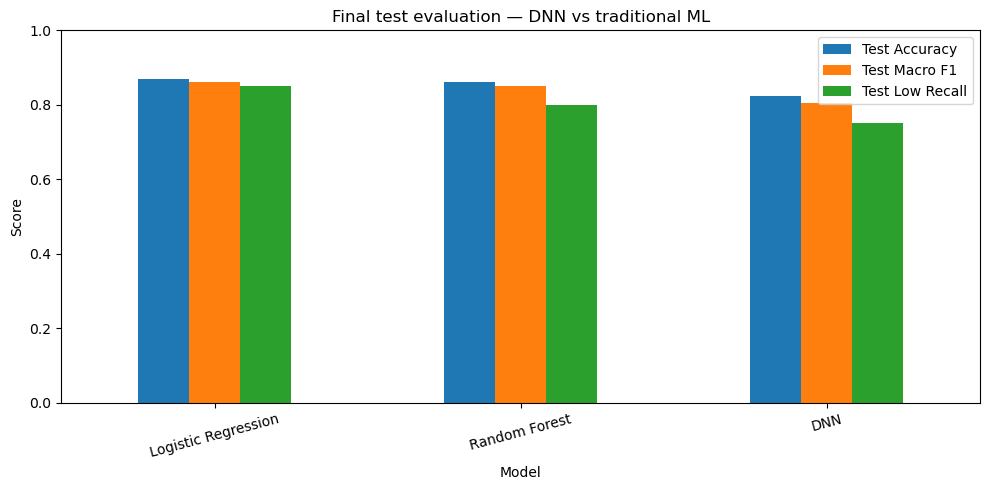

In [6]:
ax = test_results.set_index("Model")[
    ["Test Accuracy", "Test Macro F1", "Test Low Recall"]
].plot(kind="bar", figsize=(10, 5))
ax.set(title="Final test evaluation — DNN vs traditional ML",
       xlabel="Model", ylabel="Score", ylim=(0, 1))
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## 7. Detailed classification reports and confusion matrices

**Why?** A confusion matrix reveals which categories the model confuses, especially whether Low students are incorrectly predicted as Average or Good.


================ Logistic Regression ================
              precision    recall  f1-score   support

         Low       0.85      0.85      0.85        20
     Average       0.86      0.90      0.88        71
        Good       0.89      0.82      0.85        39

    accuracy                           0.87       130
   macro avg       0.87      0.86      0.86       130
weighted avg       0.87      0.87      0.87       130


================ Random Forest ================
              precision    recall  f1-score   support

         Low       0.89      0.80      0.84        20
     Average       0.82      0.96      0.88        71
        Good       0.97      0.72      0.82        39

    accuracy                           0.86       130
   macro avg       0.89      0.83      0.85       130
weighted avg       0.87      0.86      0.86       130


================ DNN ================
              precision    recall  f1-score   support

         Low       0.71      0.75      0

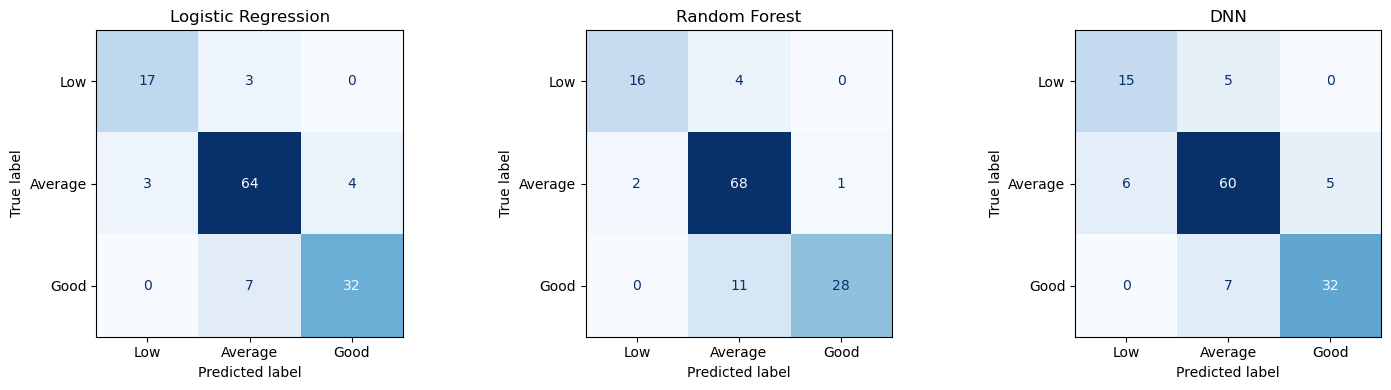

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    print("\n" + "=" * 16 + f" {name} " + "=" * 16)
    print(classification_report(y_test, pred, labels=LABELS, zero_division=0))
    cm = confusion_matrix(y_test, pred, labels=LABELS)
    ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=LABELS
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 8. Save final test results

Save the metrics and test confusion matrices as reproducible records. These files are reports, **not additional model training**.

In [8]:
MODELS_DIR.mkdir(exist_ok=True, parents=True)
test_results.to_csv(MODELS_DIR / "final_test_comparison.csv", index=False)

confusion_matrices = {
    name: confusion_matrix(y_test, pred, labels=LABELS).tolist()
    for name, pred in predictions.items()
}
evaluation_record = {
    "evaluation": "one_time_reserved_test_set",
    "dataset": "student-por.csv",
    "seed": SEED,
    "test_size": len(X_test),
    "features": features,
    "label_order": LABELS,
    "metrics": results,
    "confusion_matrices": confusion_matrices,
    "model_selection_used_test_set": False,
    "deployed_model": "DNN",
    "deployed_model_reason": (
        "Project requires a DNN application; the DNN was selected before test "
        "evaluation using validation macro F1."
    ),
}
(MODELS_DIR / "final_test_evaluation.json").write_text(
    json.dumps(evaluation_record, indent=2), encoding="utf-8"
)
print("Saved final_test_comparison.csv and final_test_evaluation.json")

Saved final_test_comparison.csv and final_test_evaluation.json


## 9. Prepare the final DNN files for Streamlit

We deploy the **validation-selected DNN** from Notebook 03, irrespective of which model gets the highest test score. This avoids choosing based on the test set.

Copy the *already-trained* DNN and preprocessing files to clear deployment filenames:
- `final_dnn.keras`
- `final_preprocessor.joblib`
- `final_label_encoder.joblib`
- `final_model_metadata.json`

The metadata records required inputs, their types, and class names. **No retraining happens here.**

In [9]:
shutil.copy2(REQUIRED["dnn"], MODELS_DIR / "final_dnn.keras")
shutil.copy2(REQUIRED["dnn_preprocessor"], MODELS_DIR / "final_preprocessor.joblib")
shutil.copy2(REQUIRED["dnn_encoder"], MODELS_DIR / "final_label_encoder.joblib")

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

# Categories are read from the FITTED training-only OneHotEncoder, not refitted on all rows.
fitted_ohe = dnn_preprocessor.named_transformers_["cat"]
training_categories = {
    feature: [str(value) for value in categories]
    for feature, categories in zip(categorical_features, fitted_ohe.categories_)
}
numeric_ranges = {
    feature: {
        "min": float(X_train[feature].min()),
        "max": float(X_train[feature].max()),
        "integer": bool(pd.api.types.is_integer_dtype(X_train[feature]))
    }
    for feature in numeric_features
}

app_metadata = {
    "project": "Student Academic Performance Prediction",
    "prediction_stage": "after_G2",
    "model_type": "Deep Neural Network",
    "selected_features": features,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "categorical_options_from_training": training_categories,
    "numeric_ranges_from_training": numeric_ranges,
    "class_names": dnn_encoder.classes_.tolist(),
    "target_definition": {
        "Low": "G3 0–9", "Average": "G3 10–13", "Good": "G3 14–20"
    },
    "dataset_context": "UCI Student Performance, Portuguese-language course",
    "research_only": True,
    "selected_using": "validation_macro_f1",
    "test_set_not_used_for_model_selection": True
}
(MODELS_DIR / "final_model_metadata.json").write_text(
    json.dumps(app_metadata, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("PASS — Final Streamlit model files prepared.")
print("Required form fields:", features)

PASS — Final Streamlit model files prepared.
Required form fields: ['G1', 'G2', 'failures', 'higher', 'absences', 'studytime', 'school', 'Fedu', 'Medu', 'Mjob', 'Dalc', 'famrel']


## 10. Verify the deployment files

Reload the final DNN, preprocessor and label encoder, and check that predictions match the already-evaluated DNN.

**Why?** Streamlit must reproduce the same output as our notebook for the same student inputs.

In [10]:
final_dnn = tf.keras.models.load_model(MODELS_DIR / "final_dnn.keras")
final_preprocessor = joblib.load(MODELS_DIR / "final_preprocessor.joblib")
final_encoder = joblib.load(MODELS_DIR / "final_label_encoder.joblib")
final_metadata = json.loads(
    (MODELS_DIR / "final_model_metadata.json").read_text(encoding="utf-8")
)

reload_probs = final_dnn.predict(
    final_preprocessor.transform(X_test).astype("float32"),
    verbose=0
)
np.testing.assert_allclose(
    reload_probs, dnn_probabilities, atol=1e-6, rtol=1e-5
)
assert final_metadata["selected_features"] == features
assert final_encoder.classes_.tolist() == dnn_encoder.classes_.tolist()
print("PASS — Final DNN reloads and reproduces the same predictions.")
print("Next: Build app.py using final_model_metadata.json and the saved artifacts.")

PASS — Final DNN reloads and reproduces the same predictions.
Next: Build app.py using final_model_metadata.json and the saved artifacts.


## 11. Final conclusion and viva-ready explanation

> We trained and selected our models using training and validation data. After completing model selection, we evaluated the saved DNN, Logistic Regression and Random Forest models once on a reserved test set of 130 students. We compared accuracy, macro precision, macro recall, macro F1, Low-class recall and confusion matrices. We kept the DNN as our deployment model because our assignment focuses on deep learning and it was selected using validation performance before the test evaluation. We saved its fitted preprocessing and label mapping so the Streamlit application can reproduce predictions.

### Responsible-use note
This is an educational demonstration using a dataset from Portuguese schools. Predictions should **not** be used alone to determine a student's employability, academic opportunities or access to support. Model performance and fairness may differ in other settings.

### Next step
**Streamlit web application:** enter the 12 selected student features, including G1 and G2, and display the predicted category with class probabilities.
